# Diffraction by a slit, two slits and a circular aperture

An aperture changes a wave's spatial spectrum. A slit spreads the field mainly
across its narrow direction; two slits add interference fringes; a circular hole
produces a central spot with rings. We will follow these fields away from the
screen and compare a circular aperture with the far-field Airy approximation.

The screen is modeled by **prescribing the transmitted transverse field**.
This is a thin-screen transmission model with a finite edge transition, not a
solved conducting-edge boundary problem. The transition length is one wavelength
and is an explicit parameter of the aperture, rather than an unresolved sharp edge. Vector angular-spectrum propagation then supplies E, H and longitudinal
E in homogeneous air. We discard evanescent terms because the observation planes
are many wavelengths from the screen. Grid size and spacing are editable below.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from numpy.testing import assert_allclose
from vecdiff_general.visualization import plot_polarization

%matplotlib inline

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)

um = 1e-6
wavelength = 0.532 * um


def observation_window(field, radius):
    window_u = abs(field.grid.u) <= radius
    window_v = abs(field.grid.v) <= radius
    grid = optics.CartesianGrid(
        field.grid.u[window_u], field.grid.v[window_v], field.grid.frame
    )

    return optics.ElectricField(
        grid, field.electric.wavelength0, field.electric.values[window_v][:, window_u]
    )

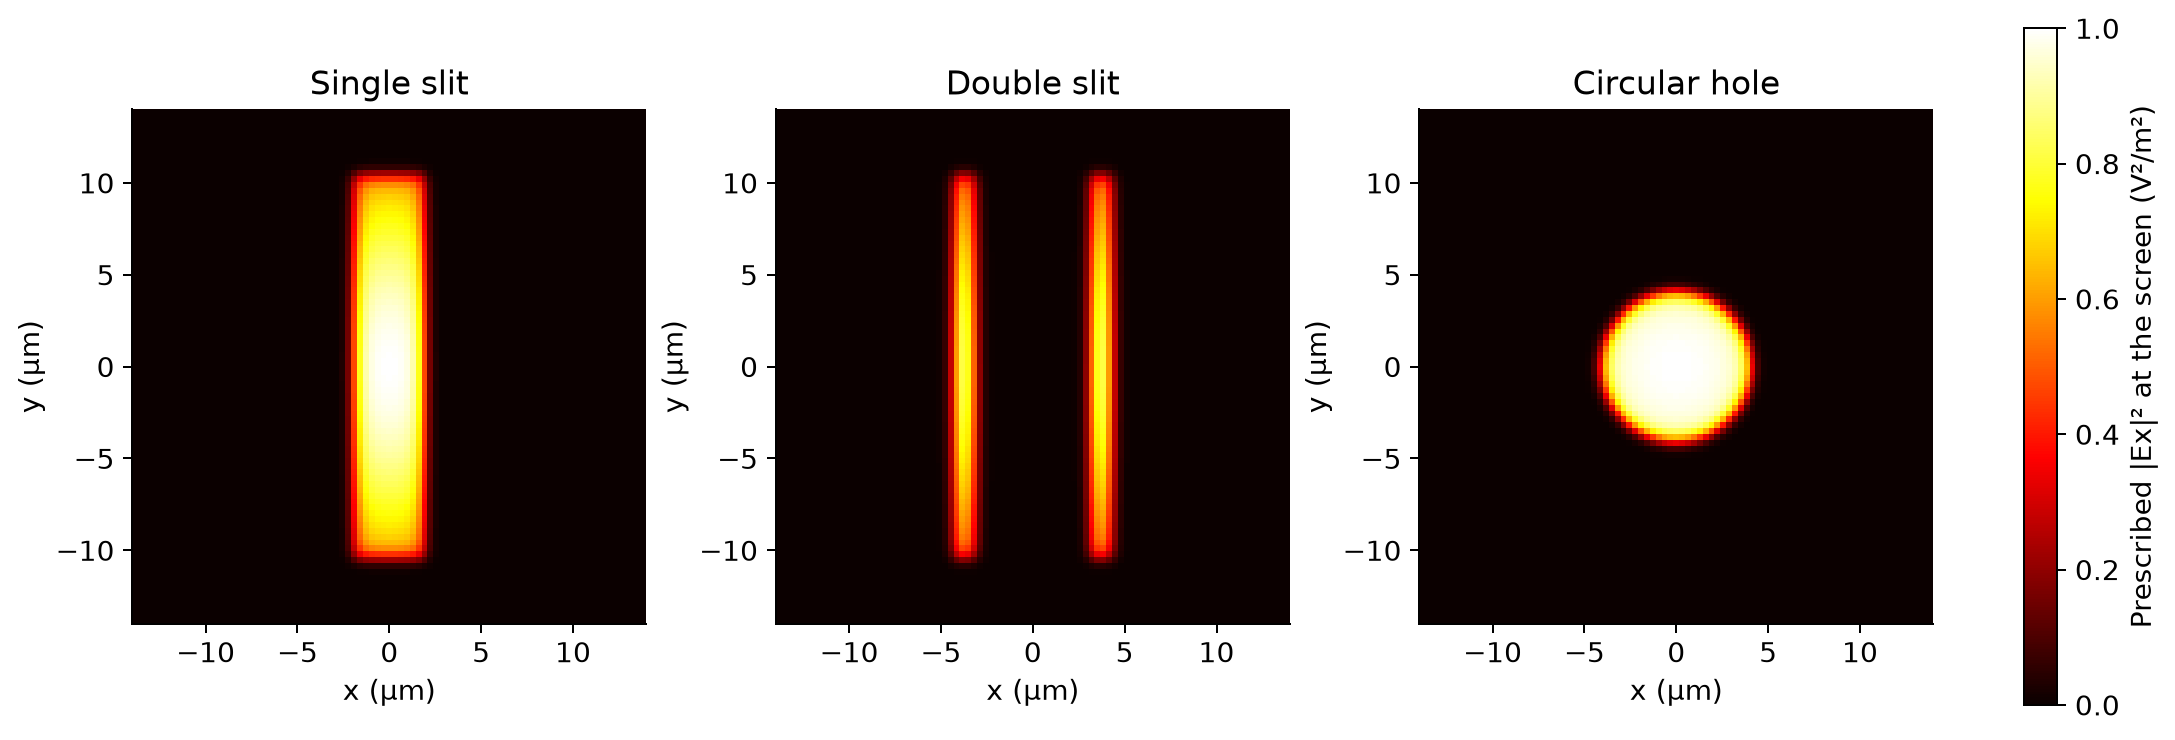

In [2]:
from matplotlib.colors import LogNorm
from scipy.special import j1

count = 768
spacing = 0.6 * wavelength
axis = (np.arange(count) - count // 2) * spacing
grid = optics.CartesianGrid(axis, axis)
X, Y = np.meshgrid(axis, axis)
illumination = np.exp(-(X**2 + Y**2) / (40 * wavelength) ** 2)
air = optics.HomogeneousRegion("air", optics.Dielectric(1))

slit_width = 8 * wavelength
slit_height = 40 * wavelength
separation = 14 * wavelength
hole_radius = 8 * wavelength

edge_width = wavelength


def edge_transmission(signed_distance):
    """Amplitude transmission, from zero outside to one inside the opening."""
    return 0.5 * (1 + np.tanh(signed_distance / edge_width))


height_transmission = edge_transmission(slit_height / 2 - abs(Y))
slit = edge_transmission(slit_width / 2 - abs(X)) * height_transmission
left_slit = edge_transmission(1.5 * wavelength - abs(X + separation / 2))
right_slit = edge_transmission(1.5 * wavelength - abs(X - separation / 2))
two_slits = (1 - (1 - left_slit) * (1 - right_slit)) * height_transmission
circle = edge_transmission(hole_radius - np.hypot(X, Y))
apertures = {"Single slit": slit, "Double slit": two_slits, "Circular hole": circle}

spectra = {}
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")

for ax, (name, opening) in zip(axes, apertures.items()):
    transverse = np.zeros(grid.shape + (2,), dtype=complex)
    transverse[..., 0] = illumination * opening
    field = optics.TransverseElectricField(grid, wavelength, transverse)
    spectra[name] = optics.angular_spectrum(field, air, evanescent="discard")

    image = ax.pcolormesh(
        axis / um,
        axis / um,
        abs(transverse[..., 0]) ** 2,
        cmap="hot",
        vmin=0,
        vmax=1,
        shading="auto",
    )
    ax.set(
        xlabel="x (µm)",
        ylabel="y (µm)",
        title=name,
        xlim=(-14, 14),
        ylim=(-14, 14),
        aspect="equal",
    )

fig.colorbar(image, ax=axes, label="Prescribed |Ex|² at the screen (V²/m²)")
plt.show()

## Watch the diffraction pattern evolve

Every panel below uses the same logarithmic scale in V²/m². The plotting window
is a crop of a larger periodic FFT cell. Increase the cell if diffracted light
reaches its edges; otherwise periodic copies can interfere with the experiment.

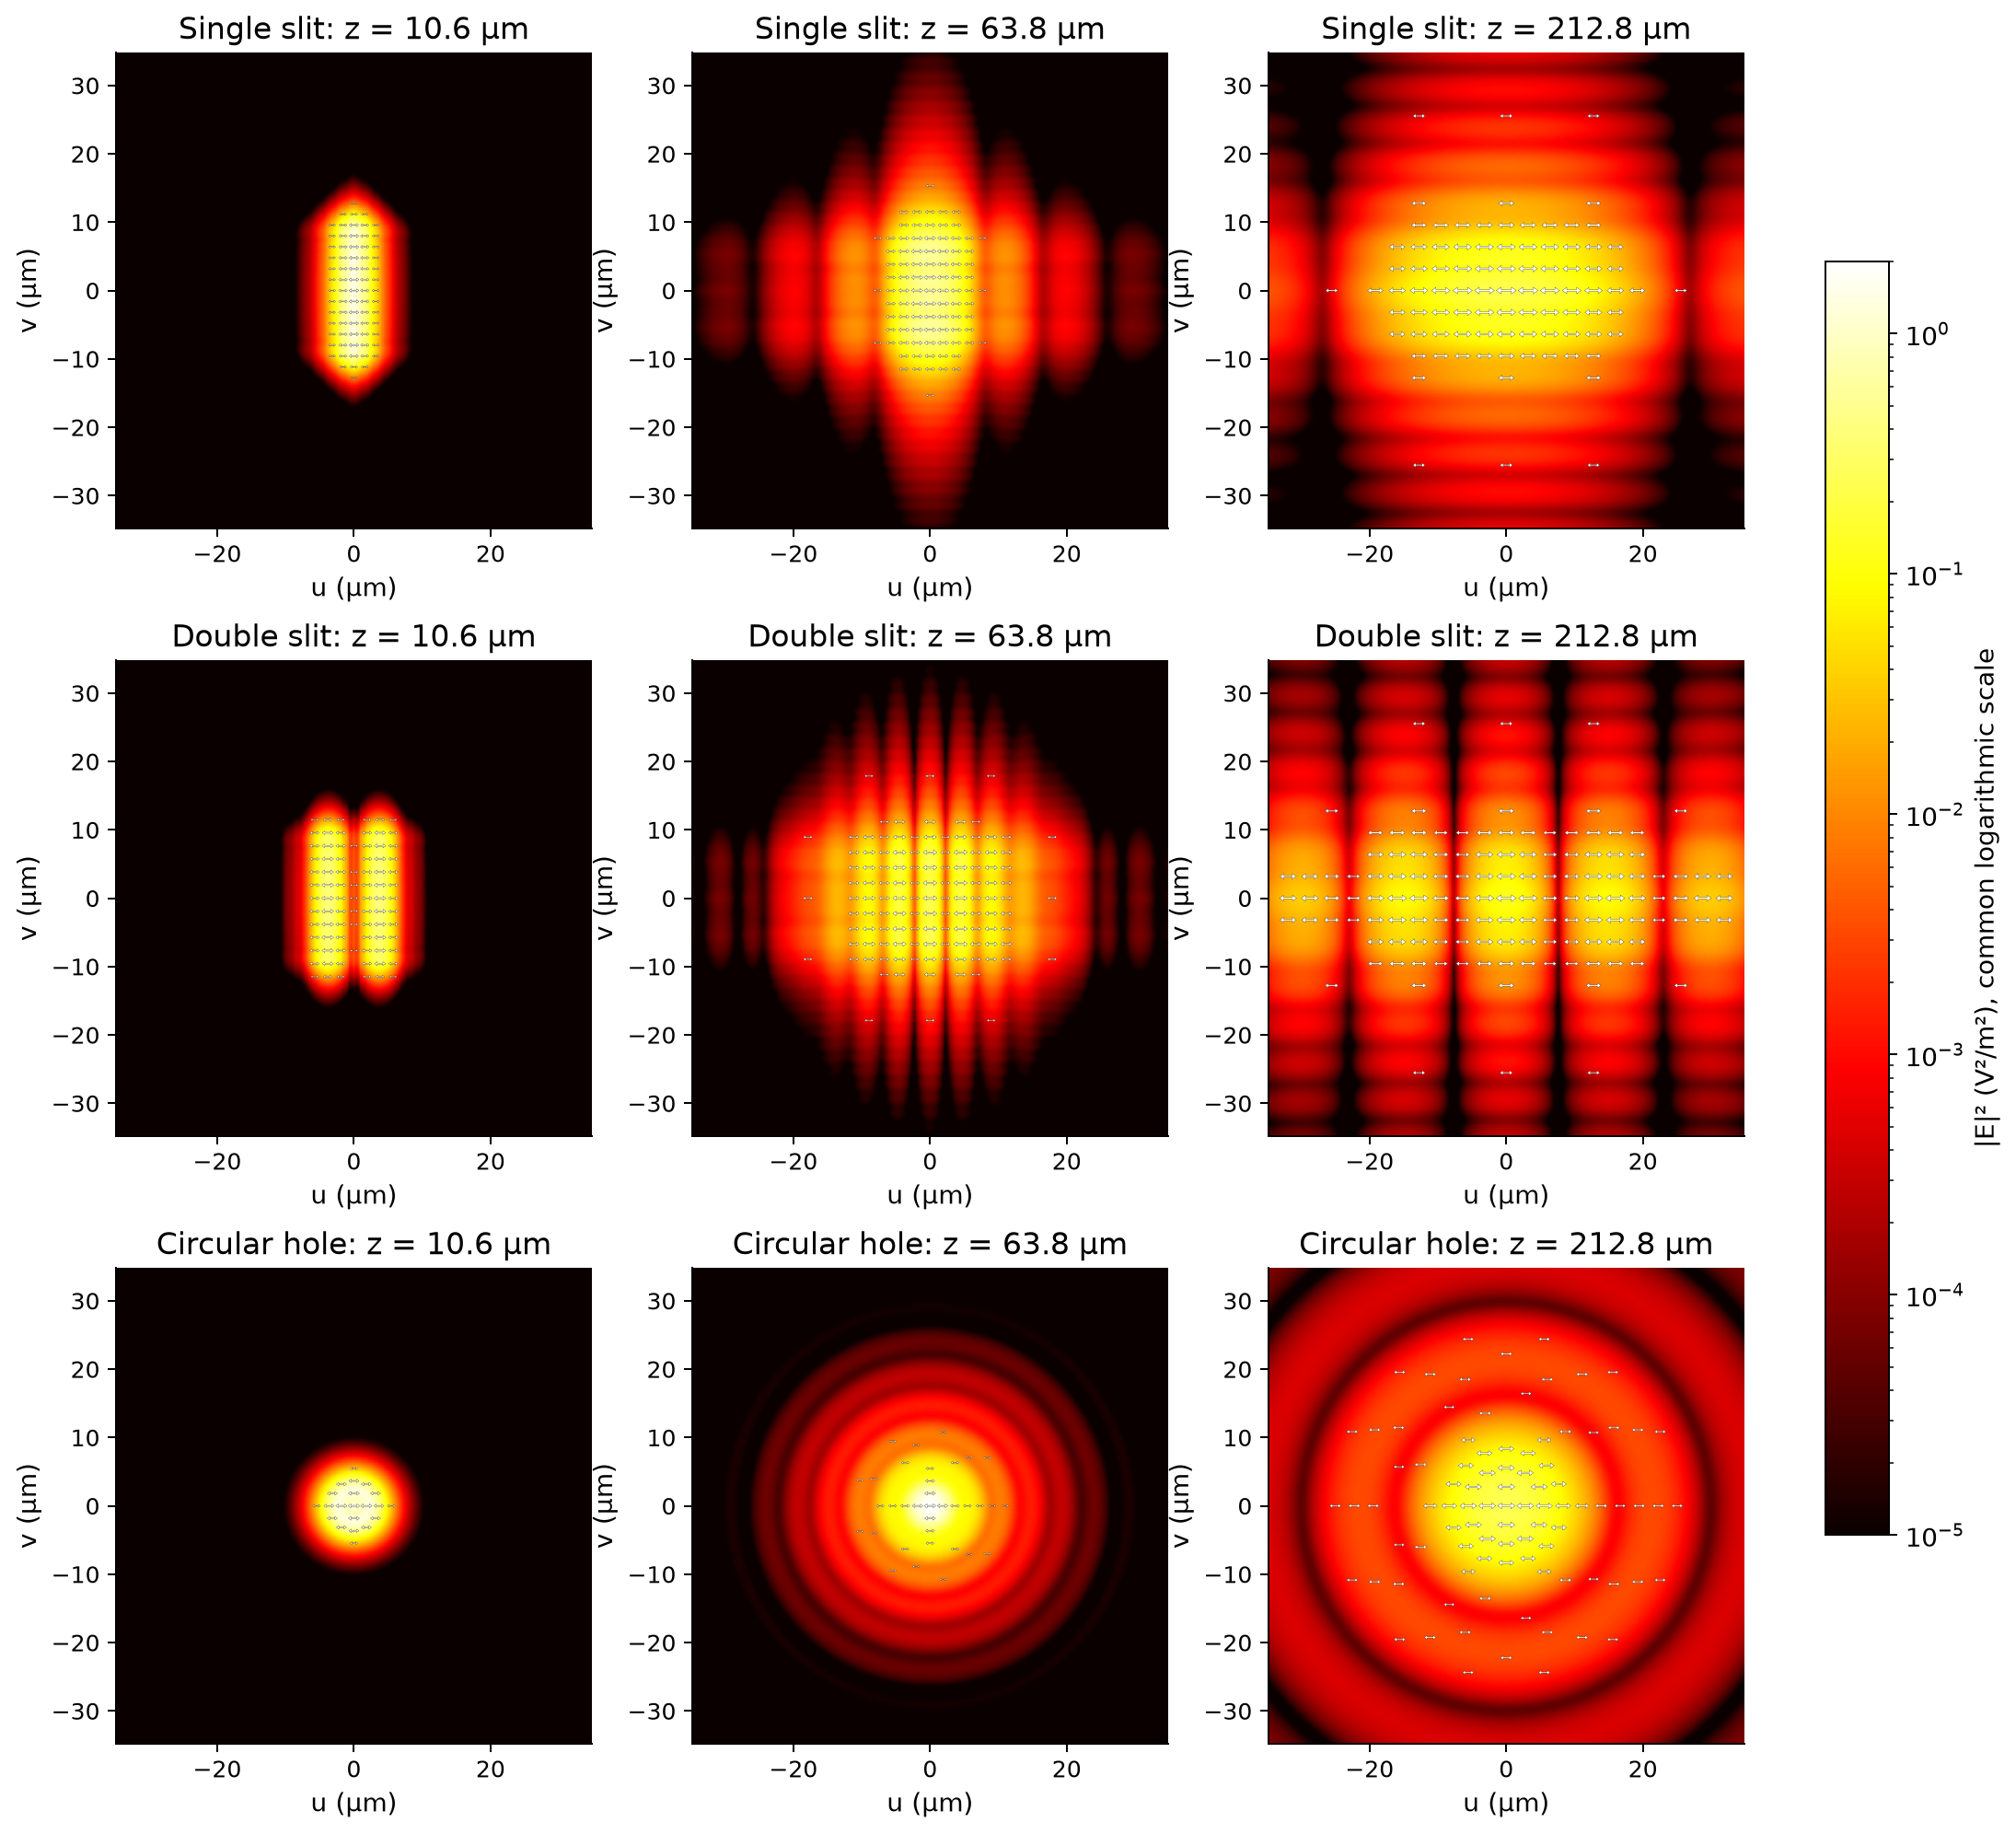

In [3]:
distances = np.array([20, 120, 400]) * wavelength
fig, axes = plt.subplots(3, 3, figsize=(12, 11), layout="constrained")

for row, (name, spectrum) in enumerate(spectra.items()):
    input_power = spectrum.propagate(0).power()

    for column, distance in enumerate(distances):
        field = spectrum.propagate(distance)
        image = axes[row, column].pcolormesh(
            axis / um,
            axis / um,
            field.electric.norm2(),
            cmap="hot",
            norm=LogNorm(vmin=1e-5, vmax=2),
            shading="gouraud",
        )
        axes[row, column].set(
            xlabel="x (µm)",
            ylabel="y (µm)",
            aspect="equal",
            xlim=(-35, 35),
            ylim=(-35, 35),
            title=f"{name}: z = {distance / um:.1f} µm",
        )
        plot_polarization(
            observation_window(field, 35 * um),
            axis=axes[row, column],
            background=False,
            colorbar=False,
            legend=False,
            crop=False,
            distribution="polar" if name == "Circular hole" else "cartesian",
            title=f"{name}: z = {distance / um:.1f} µm",
        )
        assert_allclose(field.power(), input_power, rtol=2e-12)

fig.colorbar(
    image, ax=axes, label="|E|² (V²/m²), common logarithmic scale", shrink=0.75
)
plt.show()

The two-slit modulation comes from coherent field addition; summing the two
separate intensities would erase the fringes. Narrowing either slit broadens
its diffraction envelope, while increasing their separation makes the fringes
closer together.

## A circular hole and the Airy approximation

Far from the screen, a uniformly illuminated circular hole has the scalar
paraxial profile $[2J_1(u)/u]^2$, where $u=2\pi a x/(\lambda z)$.
Our illumination is weakly Gaussian, the aperture edge has a finite transition,
and the field remains vectorial, so this is
an approximate reference rather than a forced match. The first zero occurs
near $x=0.61\lambda z/a$.

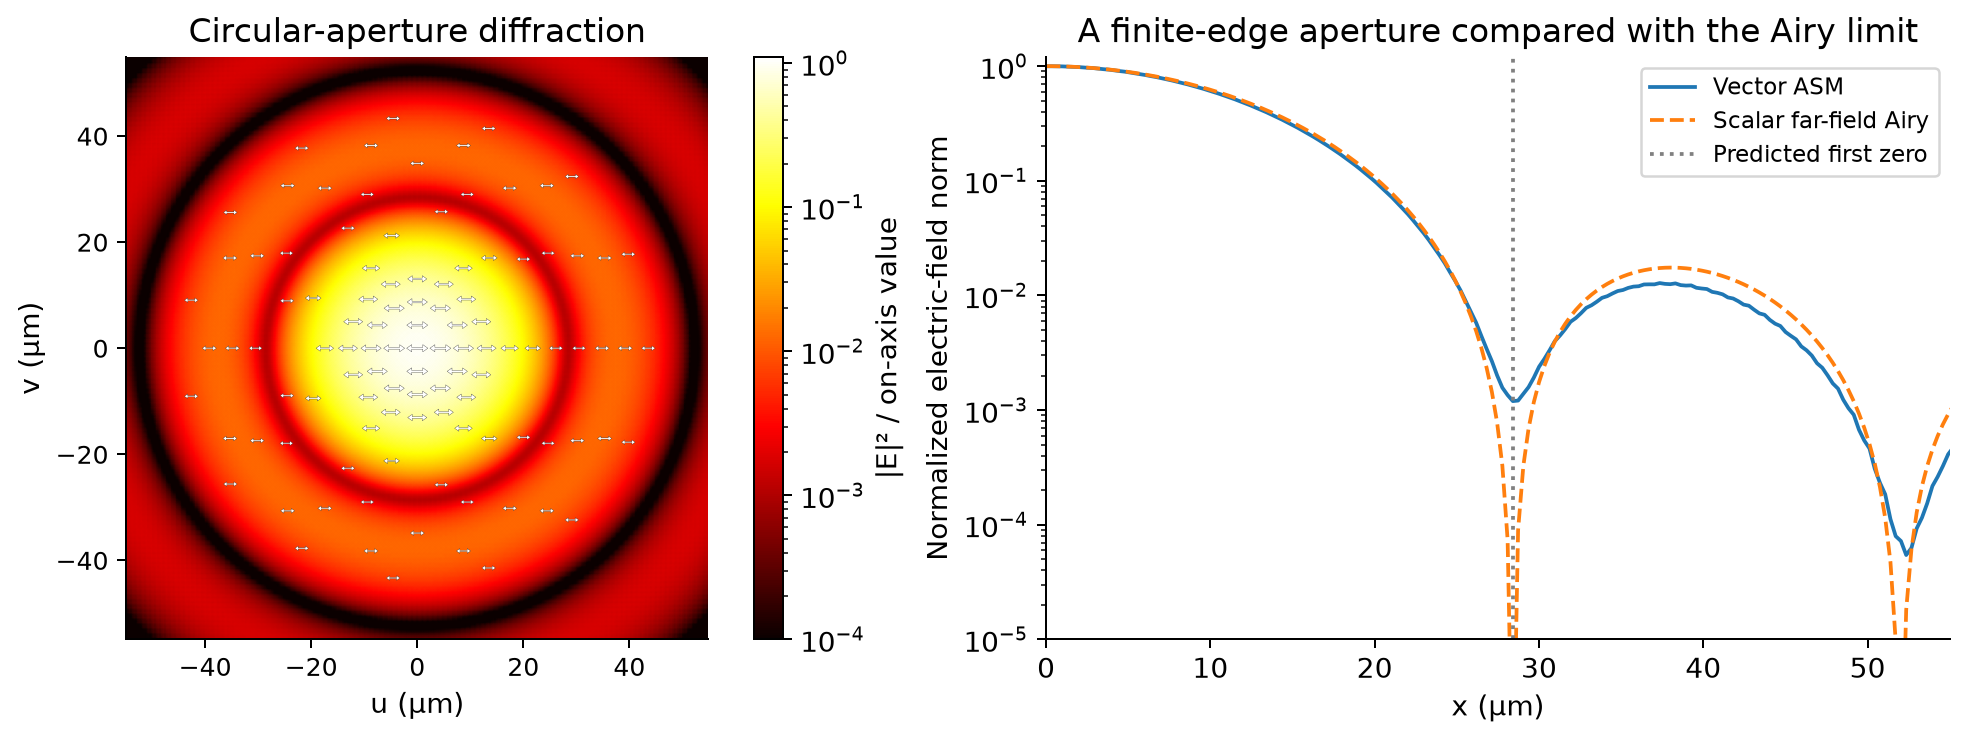

Maximum normalized-profile change when widening the FFT cell: 0.00245


In [4]:
distance = 700 * wavelength
field = spectra["Circular hole"].propagate(distance)
center = count // 2
profile = field.electric.norm2()[center]
profile = profile / profile[center]
u = 2 * np.pi * hole_radius * axis / (wavelength * distance)
airy_amplitude = np.divide(2 * j1(u), u, out=np.ones_like(u), where=u != 0)
first_zero = 0.61 * wavelength * distance / hole_radius

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
image = axes[0].pcolormesh(
    axis / um,
    axis / um,
    field.electric.norm2() / field.electric.norm2()[center, center],
    cmap="hot",
    norm=LogNorm(vmin=1e-4, vmax=1.1),
    shading="gouraud",
)
axes[0].set(
    xlabel="x (µm)",
    ylabel="y (µm)",
    title="Circular-aperture diffraction",
    xlim=(-55, 55),
    ylim=(-55, 55),
    aspect="equal",
)
plot_polarization(
    observation_window(field, 55 * um),
    axis=axes[0],
    background=False,
    colorbar=False,
    legend=False,
    crop=False,
    distribution="polar",
    title="Circular-aperture diffraction",
)
fig.colorbar(image, ax=axes[0], label="|E|² / on-axis value")
axes[1].semilogy(axis / um, np.maximum(profile, 1e-7), label="Vector ASM")
axes[1].semilogy(
    axis / um, np.maximum(airy_amplitude**2, 1e-7), "--", label="Scalar far-field Airy"
)
axes[1].axvline(first_zero / um, color="gray", ls=":", label="Predicted first zero")
axes[1].set(
    xlabel="x (µm)",
    ylabel="Normalized electric-field norm",
    xlim=(0, 55),
    ylim=(1e-5, 1.2),
    title="A finite-edge aperture compared with the Airy limit",
)
axes[1].legend(fontsize=9)
plt.show()

# Check periodic-window sensitivity at the displayed cut, using the same spacing.
large_count = 1024
large_axis = (np.arange(large_count) - large_count // 2) * spacing
large_grid = optics.CartesianGrid(large_axis, large_axis)
LX, LY = np.meshgrid(large_axis, large_axis)
large_values = np.zeros(large_grid.shape + (2,), dtype=complex)
large_values[..., 0] = np.exp(-(LX**2 + LY**2) / (40 * wavelength) ** 2) * (
    edge_transmission(hole_radius - np.hypot(LX, LY))
)
large_spectrum = optics.angular_spectrum(
    optics.TransverseElectricField(large_grid, wavelength, large_values),
    air,
    evanescent="discard",
)
large_field = large_spectrum.propagate(distance)
start = (large_count - count) // 2
large_profile = large_field.electric.norm2()[large_count // 2, start : start + count]
large_profile /= large_field.electric.norm2()[large_count // 2, large_count // 2]
window = abs(axis) < 55 * um
window_change = np.max(abs(large_profile[window] - profile[window]))
print(
    f"Maximum normalized-profile change when widening the FFT cell: {window_change:.3g}"
)
assert window_change < 0.005

**Try next:** halve the slit width, double the slit separation, or rotate the
input polarization into y. Repeat with a finer spacing to resolve the aperture
edge, and with a larger cell to separate its periodic copies. The power check
covers the entire periodic plane, not just the cropped detector window. The
printed window comparison measures one numerical limitation separately from
the physical Airy approximation.